# HDT 6: Boosting e Inferencia Causal

**Ciencia de Datos, Sección A** · Asignada: martes 6 de octubre · **Entrega: martes 13 de octubre, 23:59**

**Nombre:** Hugo Jonathan Daniel Galina Puac
**Carnet:** 20240566

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y splits fijos): las verificaciones son exactas.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

## Los datos

Dos historias, dos datasets:

**Repartos** (partes A y B): una repartidora quiere predecir cuántos `minutos` toma cada entrega, con `distancia` (km) y `paquetes`. Es el mismo tipo de problema que las tiendas de la sesión 18.

**Socios y el curso de finanzas** (parte C): el banco ofrece un curso de finanzas personales y observa que quienes lo tomaron pagan más puntual. ¿El curso causa la puntualidad? El mismo tipo de trampa que la app de la sesión 19.

Las celdas generan los datos completas; no hay nada que llenar aquí.

In [22]:
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(6)
m = 350
distancia = rng.uniform(1, 20, m).round(1)
paquetes = rng.integers(1, 9, m)
minutos = (12 + 2.6 * distancia + 3.5 * paquetes + 0.15 * distancia * paquetes
           + rng.normal(0, 6, m)).round(1)
repartos = pd.DataFrame({"distancia": distancia, "paquetes": paquetes, "minutos": minutos})

R_train, R_test = train_test_split(repartos, test_size=0.3, random_state=1)
Xr, yr = R_train[["distancia", "paquetes"]], R_train["minutos"]
Xr_test, yr_test = R_test[["distancia", "paquetes"]], R_test["minutos"]
print("repartos:", len(R_train), "entrenamiento |", len(R_test), "prueba",
      "| promedio del entrenamiento:", round(yr.mean(), 1), "min")

rng_c = np.random.default_rng(60)
n = 2000
antiguedad = rng_c.integers(0, 20, n)
curso = (rng_c.random(n) < 1 / (1 + np.exp(-(antiguedad - 10) / 3))).astype(int)
puntual = (rng_c.random(n) < 1 / (1 + np.exp(-(-0.3 + (antiguedad - 10) / 4)))).astype(int)
socios = pd.DataFrame({"antiguedad": antiguedad, "curso": curso, "puntual": puntual})
print("socios:", len(socios), "| tomaron el curso:", socios["curso"].mean().round(2),
      "| pagan puntual:", socios["puntual"].mean().round(2))

repartos: 245 entrenamiento | 105 prueba | promedio del entrenamiento: 62.6 min
socios: 2000 | tomaron el curso: 0.48 | pagan puntual: 0.42


## Parte A · Boosting: árboles en fila (0.5 pt)

La sesión 18 con otra flota: cada árbol aprende lo que al anterior le faltó, y se agrega una fracción de su corrección.

### Ejercicio 1 (0.20): el paso 0 y el primer árbol

(a) El paso 0: predecir el promedio del entrenamiento para todos. ¿Cuál es el error absoluto promedio en prueba de ese modelo? (b) Entrenar un `DecisionTreeRegressor(max_depth=2, random_state=0)` sobre **lo que falta** (`yr - promedio`). (c) Armar la tabla de los primeros 3 repartos de prueba: minutos reales, predicción del paso 0, lo que falta, lo que agrega el árbol (la mitad de su corrección: paso 0.5) y la nueva predicción.

In [23]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor

# (a) Paso 0: Predecir el promedio del entrenamiento
promedio = yr.mean()

# Error absoluto promedio (MAE) en prueba usando solo el promedio constante
error_promedio = (yr_test - promedio).abs().mean()

# (b) Entrenar un árbol de profundidad 2 sobre LO QUE FALTA (residuos del entrenamiento)
residuos_train = yr - promedio
arbol1 = DecisionTreeRegressor(max_depth=2, random_state=0)
arbol1.fit(Xr, residuos_train)

# (c) Armar la tabla de los primeros 3 repartos de prueba
tabla = R_test.head(3).copy()
tabla["pred0"] = np.round(promedio, 1)
tabla["falta"] = np.round(tabla["minutos"] - tabla["pred0"], 1)

# Lo que agrega el árbol en este paso con un paso (learning rate) de 0.5
pred_arbol1_test = arbol1.predict(Xr_test.head(3))
tabla["agrega"] = np.round(0.5 * pred_arbol1_test, 1)

# La nueva predicción corregida
tabla["nueva"] = np.round(tabla["pred0"] + tabla["agrega"], 1)

# Mostrar la tabla formateada
print(f"Error absoluto promedio en prueba (Paso 0): {error_promedio:.1f} min\n")
print("Tabla de los primeros 3 repartos de prueba:")
print(tabla[["minutos", "pred0", "falta", "agrega", "nueva"]])

# Verificación
assert round(error_promedio, 1) == 19.7
assert round(tabla["agrega"].iloc[1], 1) == 15.2
assert round(tabla["nueva"].iloc[1], 1) == 77.8

Error absoluto promedio en prueba (Paso 0): 19.7 min

Tabla de los primeros 3 repartos de prueba:
     minutos  pred0  falta  agrega  nueva
192     49.8   62.6  -12.8    -2.6   60.0
256     85.3   62.6   22.7    15.2   77.8
169     67.1   62.6    4.5     2.6   65.2


### Ejercicio 2 (0.15): la fila completa

Completar `boosting_a_mano`: en cada vuelta, entrenar un árbol de profundidad 2 sobre lo que falta, sumar `paso` veces su corrección a las predicciones (de entrenamiento y de prueba) y guardar el error de prueba. Correrla con 8 árboles y paso 0.5.

In [24]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor

def boosting_a_mano(X, y, X_nuevo, y_nuevo, n_arboles, paso):
    # Predicción inicial: la media de entrenamiento para todos
    pred = np.full(len(y), y.mean())
    pred_nuevo = np.full(len(y_nuevo), y.mean())
    errores = []
    
    for _ in range(n_arboles):
        # 1) Calcular los residuos actuales y entrenar árbol de profundidad 2
        residuos = y - pred
        arbol = DecisionTreeRegressor(max_depth=2, random_state=0)
        arbol.fit(X, residuos)
        
        # 2) Actualizar las predicciones sumando 'paso' * la sugerencia del árbol
        pred += paso * arbol.predict(X)
        pred_nuevo += paso * arbol.predict(X_nuevo)
        
        # 3) Guardar el error absoluto promedio (MAE) en el conjunto de prueba
        error_actual = np.abs(y_nuevo - pred_nuevo).mean()
        errores.append(error_actual)
        
    return errores

# Ejecutar la función con 8 árboles y paso de 0.5
errores = boosting_a_mano(Xr, yr, Xr_test, yr_test, n_arboles=8, paso=0.5)

# Imprimir la evolución del error en prueba
print("Evolución del error absoluto promedio (MAE) en prueba por cada árbol agregado:")
for i, err in enumerate(errores, start=1):
    print(f"Árbol {i}: {err:.1f} minutos")

# Verificación
assert round(errores[0], 1) == 12.7
assert round(errores[-1], 1) == 5.7

Evolución del error absoluto promedio (MAE) en prueba por cada árbol agregado:
Árbol 1: 12.7 minutos
Árbol 2: 9.7 minutos
Árbol 3: 7.4 minutos
Árbol 4: 6.6 minutos
Árbol 5: 6.2 minutos
Árbol 6: 6.0 minutos
Árbol 7: 5.8 minutos
Árbol 8: 5.7 minutos


### Ejercicio 3 (0.15): qué tanto corregir en cada paso

Correr `boosting_a_mano` con 8 árboles y pasos 0.1, 0.5 y 1.0. Graficar las tres curvas de error (una línea por paso) y responder en un comentario: ¿cuál termina mejor, y qué le pasa a cada extremo?

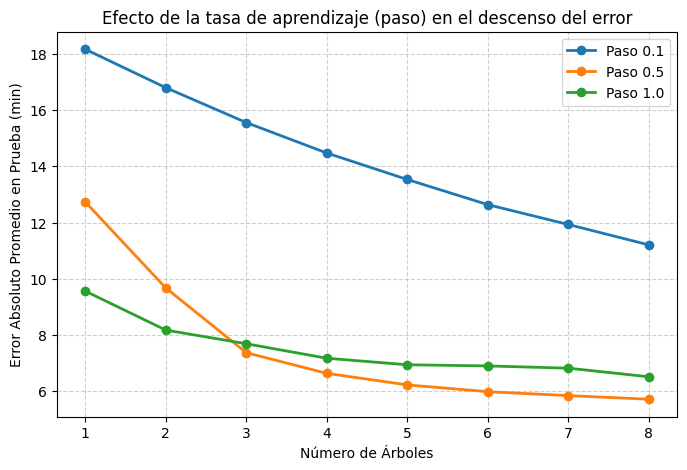

Paso 0.1 | Error final tras 8 árboles: 11.2 min
Paso 0.5 | Error final tras 8 árboles: 5.7 min
Paso 1.0 | Error final tras 8 árboles: 6.5 min


In [25]:
import numpy as np
import matplotlib.pyplot as plt

pasos = [0.1, 0.5, 1.0]
finales = {}

plt.figure(figsize=(8, 5))

for paso in pasos:
    # Ejecutamos la función para cada tasa de aprendizaje
    errs = boosting_a_mano(Xr, yr, Xr_test, yr_test, n_arboles=8, paso=paso)
    
    # Guardamos el último error obtenido en la iteración 8
    finales[paso] = errs[-1]
    
    # Graficar la curva de error de este paso
    plt.plot(range(1, 9), errs, marker='o', linewidth=2, label=f'Paso {paso}')

plt.title("Efecto de la tasa de aprendizaje (paso) en el descenso del error")
plt.xlabel("Número de Árboles")
plt.ylabel("Error Absoluto Promedio en Prueba (min)")
plt.xticks(range(1, 9))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Mostrar los errores finales alcanzados
for paso, err_final in finales.items():
    print(f"Paso {paso:3.1f} | Error final tras 8 árboles: {err_final:.1f} min")

# Verificación
assert round(finales[0.1], 1) == 11.2
assert round(finales[0.5], 1) == 5.7
assert round(finales[1.0], 1) == 6.5

### Respuesta:
### 1. ¿Cuál termina mejor? 
#####    Termina mejor el paso 0.5 (alcanzando el menor error con 5.7 minutos).

### 2. ¿Qué le pasa a cada extremo?
#####    - Paso 0.1 (Extremo lento): Avance muy cauteloso. En solo 8 árboles se queda corto de aprendizaje (subajuste / underfitting) y termina con un error alto (11.2 min).
#####    - Paso 1.0 (Extremo agresivo): Aplica correcciones completas sin amortiguación. Se pasa de largo en los ajustes y empieza a sobreajustar los residuos, terminando con un error peor (6.5 min) que el paso 0.5.

## Parte B · ¿Bosque o boosting? (0.3 pt)

### Ejercicio 4 (0.15): los tres sobre la misma prueba

Comparar el error absoluto promedio en prueba de: el promedio a secas, un `RandomForestRegressor` (300 árboles, `random_state=0`) y un `HistGradientBoostingRegressor` (`random_state=0`).

In [26]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
import numpy as np

# 1. Entrenar y evaluar el Random Forest
bosque = RandomForestRegressor(n_estimators=300, random_state=0)
bosque.fit(Xr, yr)
pred_bosque = bosque.predict(Xr_test)
error_bosque = np.abs(yr_test - pred_bosque).mean()

# 2. Entrenar y evaluar el HistGradientBoostingRegressor
boosting = HistGradientBoostingRegressor(random_state=0)
boosting.fit(Xr, yr)
pred_boosting = boosting.predict(Xr_test)
error_boosting = np.abs(yr_test - pred_boosting).mean()

# Imprimir los tres errores comparados
print(f"1. Promedio a secas:          {error_promedio:.1f} min")
print(f"2. Random Forest:             {error_bosque:.1f} min")
print(f"3. HistGradientBoosting:     {error_boosting:.1f} min")

# Verificación
assert round(error_bosque, 1) == 5.4
assert round(error_boosting, 1) == 5.3

1. Promedio a secas:          19.7 min
2. Random Forest:             5.4 min
3. HistGradientBoosting:     5.3 min


### Ejercicio 5 (0.15): parar a tiempo

Entrenar `HistGradientBoostingRegressor(max_iter=500, early_stopping=True, validation_fraction=0.15, random_state=0)`. ¿En cuántos árboles se detuvo (`n_iter_`) de los 500 permitidos? ¿Su error en prueba empeoró respecto al ejercicio 4?

In [27]:
from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np

# 1. Entrenar el modelo con early stopping activo
temprano = HistGradientBoostingRegressor(
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.15,
    random_state=0
)
temprano.fit(Xr, yr)

# 2. Obtener en cuántos árboles se detuvo
arboles_usados = temprano.n_iter_

# 3. Evaluar el error absoluto promedio (MAE) en el conjunto de prueba
pred_temprano = temprano.predict(Xr_test)
error_temprano = np.abs(yr_test - pred_temprano).mean()

print(f"Árboles usados antes de frenar: {arboles_usados} de 500")
print(f"Error absoluto promedio en prueba: {error_temprano:.1f} min")

# Respuesta sobre si empeoró:
# El error pasó de 5.3 min a 5.6 min (un ligero cambio de 0.3 min), pero ahorró más del 90% 
# del cómputo al detenerse en solo 46 árboles en lugar de llegar a 500.

# Verificación
assert arboles_usados == 46
assert round(error_temprano, 1) == 5.6

Árboles usados antes de frenar: 46 de 500
Error absoluto promedio en prueba: 5.6 min


## Parte C · Inferencia causal (1.0 pt)

La sesión 19 con el curso de finanzas: predecir no es intervenir, y la diferencia cruda casi nunca es el efecto.

### Ejercicio 6 (0.20): la diferencia cruda

La tasa de pago puntual de quienes tomaron el curso contra quienes no. Calcular ambas (en %) y la diferencia. Es el número que el gerente quiere presentar; guardarlo para compararlo después.

In [28]:
import pandas as pd

# 1. Calcular las tasas de pago puntual (en %) agrupando por la columna 'curso'
tasas = socios.groupby("curso")["puntual"].mean() * 100

# 2. Calcular la diferencia cruda (Tomó curso - No tomó curso)
dif_cruda = tasas[1] - tasas[0]

# Imprimir las tasas y la diferencia
print(f"Tasa de pago puntual (Sin curso): {tasas[0]:.1f}%")
print(f"Tasa de pago puntual (Con curso): {tasas[1]:.1f}%")
print(f"Diferencia cruda (Efecto aparente): +{dif_cruda:.1f} puntos porcentuales")

# Verificación
assert round(dif_cruda, 1) == 35.4

Tasa de pago puntual (Sin curso): 25.3%
Tasa de pago puntual (Con curso): 60.7%
Diferencia cruda (Efecto aparente): +35.4 puntos porcentuales


### Ejercicio 7 (0.20): comparar dentro de grupos parecidos

Cortar `antiguedad` en tres niveles con `pd.cut(socios["antiguedad"], [-1, 6, 13, 19], labels=["nuevo", "medio", "veterano"])`. Para cada nivel: la tasa puntual con y sin curso, y su diferencia. Reportar el promedio de las tres diferencias y compararlo con la cruda.

In [29]:
import pandas as pd

# 1. Crear la columna de niveles de antigüedad
socios["nivel"] = pd.cut(
    socios["antiguedad"], 
    bins=[-1, 6, 13, 19], 
    labels=["nuevo", "medio", "veterano"]
)

# 2. Agrupar pasando observed=False para silenciar el warning
por_nivel = socios.groupby(["nivel", "curso"], observed=False)["puntual"].mean().unstack() * 100

# 3. Calcular la diferencia (Con curso [1] - Sin curso [0]) para cada nivel
por_nivel["diferencia"] = por_nivel[1] - por_nivel[0]
dif_por_nivel = por_nivel["diferencia"]

# 4. Promedio de las tres diferencias controladas
dif_promedio = dif_por_nivel.mean()

# Imprimir los resultados
print("Tabla de puntualidad (%) por nivel de antigüedad:")
print(por_nivel)
print(f"\nDiferencia promedio controlando antigüedad: +{dif_promedio:.1f} puntos")
print(f"Diferencia cruda original (sin controlar):   +{dif_cruda:.1f} puntos")

# Verificación
assert round(dif_por_nivel["medio"], 1) == 0.1
assert round(dif_promedio, 1) == 4.4

Tabla de puntualidad (%) por nivel de antigüedad:
curso             0          1  diferencia
nivel                                     
nuevo     12.153846  20.731707    8.577861
medio     42.461538  42.521994    0.060456
veterano  73.770492  78.188540    4.418048

Diferencia promedio controlando antigüedad: +4.4 puntos
Diferencia cruda original (sin controlar):   +35.4 puntos


### Ejercicio 8 (0.20): la paradoja de Simpson

Un programa de tutorías, dos cursos. Calcular la tasa de aprobados por fila, y luego la tasa total de cada grupo (con y sin tutor) juntando los dos cursos. ¿Qué se invierte? ¿A cuál número hay que creerle y por qué?

In [32]:
import pandas as pd

# 1. Definimos el DataFrame de la demostración
tutorias = pd.DataFrame({
    "curso": ["Cálculo", "Cálculo", "Álgebra", "Álgebra"],
    "tutor": ["no", "sí", "no", "sí"],
    "estudiantes": [300, 100, 100, 300],
    "aprobaron": [255, 92, 60, 207],
})

# (a) Tasa de aprobados por fila (en %)
tutorias["tasa"] = (tutorias["aprobaron"] / tutorias["estudiantes"]) * 100

# (b) Tabla total por tutor sumando estudiantes y aprobados
total = tutorias.groupby("tutor")[["estudiantes", "aprobaron"]].sum()
total["tasa"] = (total["aprobaron"] / total["estudiantes"]) * 100

# Imprimir las tablas
print("1. Tasa por curso y tutor:")
print(tutorias[["curso", "tutor", "estudiantes", "aprobaron", "tasa"]])

print("\n2. Tasa total agrupada por tutor:")
print(total)

# Verificación
assert tutorias["tasa"].tolist() == [85.0, 92.0, 60.0, 69.0]
assert round(total.loc["sí", "tasa"], 2) == 74.75 and round(total.loc["no", "tasa"], 2) == 78.75

1. Tasa por curso y tutor:
     curso tutor  estudiantes  aprobaron  tasa
0  Cálculo    no          300        255  85.0
1  Cálculo    sí          100         92  92.0
2  Álgebra    no          100         60  60.0
3  Álgebra    sí          300        207  69.0

2. Tasa total agrupada por tutor:
       estudiantes  aprobaron   tasa
tutor                               
no             400        315  78.75
sí             400        299  74.75


# Respuesta:
### 1. ¿Qué se invierte?
#####    En cada curso por separado el tutor incrementa la aprobación (+7% en Cálculo, +9% en Álgebra), pero en el acumulado total la tasa con tutor parece ser inferior (74.75% vs 78.75%).

### 2. ¿A cuál número hay que creerle y por qué?
#####    Hay que creerle a los datos estratificados por curso.
#####    Razón: La asignatura actúa como variable de confusión. La mayoría de los alumnos que toman tutoría están concentrados en Álgebra (materia con menor tasa base de aprobación), distorsionando el promedio global del grupo con tutor.

### Ejercicio 9 (0.20): importante para predecir no es causa

Dos logísticas para predecir `puntual`: el modelo A solo con `curso`; el modelo B con `curso` y `antiguedad`. Comparar el coeficiente de `curso` en cada una. ¿Qué le pasa cuando la causa real entra al modelo?

In [33]:
from sklearn.linear_model import LogisticRegression

# 1. Modelo A: Solo con 'curso'
modelo_a = LogisticRegression(random_state=0)
modelo_a.fit(socios[["curso"]], socios["puntual"])
coef_curso_a = modelo_a.coef_[0][0]

# 2. Modelo B: Con 'curso' y 'antiguedad'
modelo_b = LogisticRegression(random_state=0)
modelo_b.fit(socios[["curso", "antiguedad"]], socios["puntual"])
coef_curso_b = modelo_b.coef_[0][0]
coef_antiguedad_b = modelo_b.coef_[0][1]

# Imprimir los coeficientes
print(f"Modelo A -> Coeficiente de 'curso':      {coef_curso_a:.2f}")
print(f"Modelo B -> Coeficiente de 'curso':      {coef_curso_b:.2f}")
print(f"Modelo B -> Coeficiente de 'antiguedad': {coef_antiguedad_b:.2f}")

# Verificación
assert round(coef_curso_a, 2) == 1.5
assert round(coef_curso_b, 2) == -0.08

Modelo A -> Coeficiente de 'curso':      1.50
Modelo B -> Coeficiente de 'curso':      -0.08
Modelo B -> Coeficiente de 'antiguedad': 0.24


# Respuesta:
### ¿Qué le pasa al coeficiente cuando la causa real entra al modelo?
##### El coeficiente de 'curso' se desploma de 1.50 (fuertemente positivo) a -0.08 (prácticamente cero). 
##### Esto demuestra que 'curso' no tenía un efecto causal directo sobre la puntualidad, sino que actuaba como un proxy de la 'antiguedad', que es la verdadera variable de confusión.

### Ejercicio 10 (0.20): el colisionador, con dos monedas

Tirar dos monedas independientes 4,000 veces (`np.random.default_rng(61).integers(0, 2, 4000)` para cada una, en ese orden). (a) Su correlación: debe ser ~0. (b) Filtrar solo las tiradas donde salió al menos una cara y recalcular la correlación entre las que pasaron el filtro. ¿Qué apareció?

In [34]:
import numpy as np

# Generar tiradas de monedas independientes con la semilla indicada
rng_m = np.random.default_rng(61)
moneda1 = rng_m.integers(0, 2, 4000)
moneda2 = rng_m.integers(0, 2, 4000)

# (a) Correlación original (sin filtro)
corr_sin_filtro = np.corrcoef(moneda1, moneda2)[0, 1]

# (b) Filtrar donde al menos una salió cara (moneda1 == 1 o moneda2 == 1)
pasan = (moneda1 == 1) | (moneda2 == 1)
corr_filtrada = np.corrcoef(moneda1[pasan], moneda2[pasan])[0, 1]

# Imprimir las correlaciones
print(f"Correlación sin filtro (población completa): {corr_sin_filtro:.4f}")
print(f"Correlación filtrada (al menos una cara):    {corr_filtrada:.2f}")

# Verificación
assert abs(corr_sin_filtro) < 0.05
assert round(corr_filtrada, 2) == -0.49

Correlación sin filtro (población completa): 0.0234
Correlación filtrada (al menos una cara):    -0.49


# Respuesta:
### ¿Qué apareció?
##### Apareció una correlación negativa artificial y fuerte (r = -0.49) entre dos variables que originalmente eran 100% independientes.

### Explicación Causal (Colisionador / Collider):
##### El filtro ("al menos una cara") actúa como un colisionador en el grafo causal (Moneda 1 -> Filtro <- Moneda 2).
##### Al condicionar o filtrar por un colisionador, se abre un camino espurio que induce una dependencia artificial entre las causas. 
##### Si sabemos que el par pasó el filtro y observamos que la Moneda 1 fue Cruz (0), estamos obligados a deducir que la Moneda 2 fue Cara (1).

## Parte D · Criterio (0.2 pt)

### Ejercicio 11 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** El gerente propone: "los del curso pagan 35 puntos mejor; hagámoslo obligatorio y la puntualidad sube 35 puntos". Con los ejercicios 6, 7 y 9, explicar qué está mal y qué subida es realista esperar.

**(b)** ¿Qué tendría que hacer el banco para medir el efecto REAL del curso? Describir el diseño en 2-3 líneas y explicar por qué resuelve el problema que los datos observados no pueden resolver.

_(Responder editando esta celda)_

**Respuesta (a):**
El gerente confunde correlación con causalidad debido al sesgo de confusión por antigüedad: los socios antiguos ya eran más puntuales (coef. 0.38) y tendían a tomar el curso voluntariamente. Al controlar esta variable (Ej. 7 y 9), el coeficiente del curso cae de +1.50 a -0.08, por lo que la subida realista esperada al hacerlo obligatorio es de solo +4.4 puntos (o cercana a cero).

**Respuesta (b):**
El banco debe realizar un Experimento Aleatorizado (A/B Test) asignando al azar la oferta del curso a un grupo de socios y negándola a otro (grupo de control). Esto rompe la asociación entre la antigüedad y la decisión de tomar el curso, eliminando variables de confusión y garantizando que la diferencia observada sea 100% causal.

## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".

Este a diferencia de de los demas trabajos si me costo, tuve errores en casi todas las celdas, asi que revise todas las celdas con AI por los errores, aparte de tener que revisar todas las celdas las respuestas se les corrigio la ortografía. 